# General error bound $\varepsilon$

This notebook illustrates the general error bound:

$$
\varepsilon \equiv 
\tfrac{2\pi \, \Omega^{2} \, 2^{q}}{(2 \, \Delta z)^{2q}} \, 
\int\limits_{k_{\varepsilon}}^{\infty}
e^{- 2 \, \Delta z \, k } \, k^{2q-1} \, (2 \, \Delta z)^{2q}
\: d k \: ,
\quad \Delta z = z^{t}_{0} - z^{\dagger}_{0} > 0 \: .
$$

Note that, by using the following change of variables in the integral above:

$$
k = \frac{t}{2 \, \Delta z}
$$

and
$$
k_{\varepsilon} = \frac{x}{2 \, \Delta z} \: , 
$$

we obtain that

$$
\int\limits_{k_{\varepsilon}}^{\infty}
e^{- 2 \, \Delta z \, k } \, k^{2q-1} \, (2 \, \Delta z)^{2q}
\: d k =
\Gamma\left(2q, 2 \, \Delta z \, k_{\varepsilon} \right) \: ,
$$

where 

$$
\Gamma\left(2q, 2 \, \Delta z \, k_{\varepsilon} \right) = 
\int\limits_{2 \, \Delta z \, k_{\varepsilon}}^{\infty}
e^{- t } \, t^{2q-1} \: d t
$$ 

is the Incomplete Gamma Function (Gradshteyn and Ryzhik, 2007, p. 899). The results are computed via numerical integration and by using [`scipy.special`](https://docs.scipy.org/doc/scipy/reference/special.html).

For simplicity, we consider here that $2\pi \, \Omega^{2} = 1$.

##### References

* Gradshteyn, I. S., and I. M. Ryzhik, 2007, Table of integrals, series, and products, 7 ed.:
Elsevier. (Translated from Russian by Scripta Technica, Inc.).

In [1]:
import numpy as np
from scipy.integrate import quad
from matplotlib import pyplot as plt

The integrand $e^{- 2 \, \Delta z \, k } \, k^{2q-1} \, (2 \, \Delta z)^{2q}$

In [2]:
# Function for evaluating the integrand of the required Incomplete Gamma Function
def integrand(k, Dz, q):
    return np.exp(-2*Dz*k)*(k**(2*q-1))*((2*Dz)**(2*q))

Distance $\Delta z$ from continuation plane $z^{\dagger}_{0}$ and top of the sources $z^{t}_{0}$

In [3]:
Dz = 350.

Order $q$ of the differential operator acting on the observed potential field

In [4]:
q = [0, 1, 2]

#### Plot $\varepsilon \times k$ for $0< k < 1$

In [7]:
#ke = np.linspace(0.05, 0.10, 100)
ke = np.linspace(1e-7, 6e-2, 500)

In [8]:
epsilon = []
for qi in q:
    epsilon_q = []
    for kei in ke:
        result, error = quad(integrand, kei, np.inf, args=(Dz, qi))
        epsilon_q.append(result)
    epsilon.append(epsilon_q)

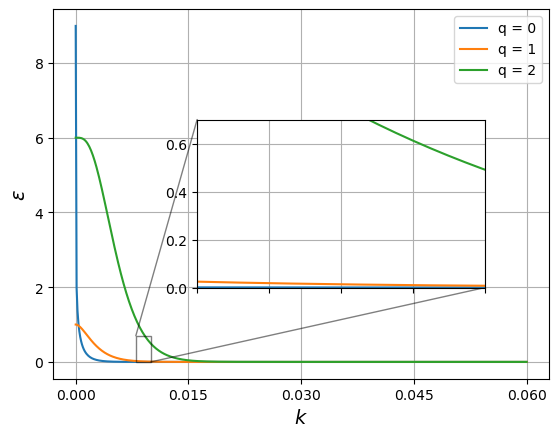

In [20]:
fig, ax = plt.subplots()

for epsilon_q, qi in zip(epsilon, q):
    ax.plot(ke, epsilon_q, label='q = {}'.format(qi))
ax.set_xlabel('$k$', fontsize=14)
ax.set_ylabel('$\\varepsilon$', fontsize=14)
#ax.set_yscale('log')
ax.set_xticks(np.linspace(np.min(ke), np.max(ke), 5))
#x.set_yticks(np.linspace(np.min(epsilon), np.max(epsilon), 5))
# ax.set_xlim(0.0875, 0.1)
# ax.set_ylim(0, 1e-9)
ax.grid()
ax.legend(loc='best')

# # inset axes
#inset = fig.add_axes([left, bottom, width, height])
inset = fig.add_axes([0.35, 0.30, 0.45, 0.35])

for epsilon_q, qi in zip(epsilon, q):
    inset.plot(ke, epsilon_q)

# # subregion of the original image
inset.set_xlim(8e-3, 1e-2)
inset.set_ylim(-1e-5, 7e-1)
inset.set_xticklabels([])
#inset.set_yticklabels([])
inset.grid()

ax.indicate_inset_zoom(inset, edgecolor="black")

plt.show()